In [2]:
# IMPORTS
import os
import sys
import ast
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time
from matplotlib.patches import Patch

sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# METRICS

In [3]:
workflow_files = {
    '8B_Baseline': 'Outputs_Evaluation/MultiDB_Experiment/BASELINE/500_test_llama_3_1_8b_baseline.xlsx',
    '8B_Gen_Helper_History': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_HISTORY/500_test_llama_3_1_8b_gen_helper_history.xlsx',
    '8B_Gen_Helper_Trajectory': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_TRAJ/500_test_llama_3_1_8b_gen_helper_traj.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/MultiDB_Experiment/HISTORY_ONLY/500_test_llama_3_1_8b_history_only.xlsx',
    '8B_Trajectory_History': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_HISTORY/500_test_llama_3_1_8b_traj_history.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_ONLY/500_test_llama_3_1_8b_traj_only.xlsx',
    '8B_Memory_All_In': 'Outputs_Evaluation/MultiDB_Experiment/MEMORY_ALL_IN/500_test_llama_3_1_8b_mem_all_in.xlsx',

    '7B_Baseline': 'Outputs_Evaluation/MultiDB_Experiment/BASELINE/500_test_qwen_2_5_7b_baseline.xlsx',
    '7B_Gen_Helper_History': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_HISTORY/500_test_qwen_2_5_7b_gen_helper_history.xlsx',
    '7B_Gen_Helper_Trajectory': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_TRAJ/500_test_qwen_2_5_7b_gen_helper_traj.xlsx',
    '7B_History_Only': 'Outputs_Evaluation/MultiDB_Experiment/HISTORY_ONLY/500_test_qwen_2_5_7b_history_only.xlsx',
    '7B_Trajectory_History': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_HISTORY/500_test_qwen_2_5_7b_traj_history.xlsx',
    '7B_Trajectory_Only': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_ONLY/500_test_qwen_2_5_7b_traj_only.xlsx',
    '7B_Memory_All_In': 'Outputs_Evaluation/MultiDB_Experiment/MEMORY_ALL_IN/500_test_qwen_2_5_7b_mem_all_in.xlsx',

    '3B_Baseline': 'Outputs_Evaluation/MultiDB_Experiment/BASELINE/500_test_llama_3_2_3b_baseline.xlsx',
    '3B_Gen_Helper_History': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_HISTORY/500_test_llama_3_2_3b_gen_helper_history.xlsx',
    '3B_Gen_Helper_Trajectory': 'Outputs_Evaluation/MultiDB_Experiment/GEN_HELPER_TRAJ/500_test_llama_3_2_3b_gen_helper_traj.xlsx',
    '3B_History_Only': 'Outputs_Evaluation/MultiDB_Experiment/HISTORY_ONLY/500_test_llama_3_2_3b_history_only.xlsx',
    '3B_Trajectory_History': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_HISTORY/500_test_llama_3_2_3b_traj_history.xlsx',
    '3B_Trajectory_Only': 'Outputs_Evaluation/MultiDB_Experiment/TRAJECTORY_ONLY/500_test_llama_3_2_3b_traj_only.xlsx',
    '3B_Memory_All_In': 'Outputs_Evaluation/MultiDB_Experiment/MEMORY_ALL_IN/500_test_llama_3_2_3b_mem_all_in.xlsx'
}

model_mapping = {
    '8B': 'llama_3_1_8b',
    '7B': 'qwen_2_5_7b',
    '3B': 'llama_3_2_3b'
}

summary_results = []

def count_corrector_iterations(path):
    if pd.isna(path):
        return 0
    try:
        parsed_path = ast.literal_eval(str(path))
        if isinstance(parsed_path, list):
            return parsed_path.count('cypher_corrector')
    except (ValueError, SyntaxError):
        pass
    return str(path).count('cypher_corrector')

def is_evaluation_complete(df, expected_rows):
    if len(df) != expected_rows or 'generated_cypher' not in df.columns or 'Syntax Valid' not in df.columns:
        return False
    rows_to_evaluate = df['generated_cypher'].notna()
    return df.loc[rows_to_evaluate, 'Syntax Valid'].notna().all()

def evaluation_progress(df):
    if 'generated_cypher' not in df.columns or 'Syntax Valid' not in df.columns:
        return 0, len(df)
    rows_to_evaluate = df['generated_cypher'].notna()
    total = rows_to_evaluate.sum()
    completed = df.loc[rows_to_evaluate, 'Syntax Valid'].notna().sum()
    return completed, total

total_start = time.time()

for file_number, (config_name, file_path) in enumerate(workflow_files.items(), start=1):
    file_start = time.time()
    print(f"\n--- [{file_number}/{len(workflow_files)}] Processing: {config_name} ---")

    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue

    workflow_df = pd.read_excel(file_path).astype(object)
    expected_rows = len(workflow_df)

    model_key = config_name.split('_')[0]
    model_name = model_mapping[model_key]
    evaluated_path = f'MultiDB_Experiment_Metrics/{model_name}/{config_name}_evaluated.xlsx'
    evaluated_pkl_path = f'MultiDB_Experiment_Metrics/{model_name}/{config_name}_evaluated.pkl'
    os.makedirs(os.path.dirname(evaluated_path), exist_ok=True)

    use_existing = False

    if os.path.exists(evaluated_path):
        existing_df = pd.read_excel(evaluated_path)

        if is_evaluation_complete(existing_df, expected_rows):
            completed, total = evaluation_progress(existing_df)
            print(f"Already complete: {completed}/{total} queries")
            evaluated_df = existing_df
            use_existing = True
        else:
            completed, total = evaluation_progress(existing_df)
            print(f"Incomplete evaluation found: {completed}/{total} queries")
            print("Resuming from existing progress...")

            # Normally calculate_scores already has a matching .pkl.
            # If only the Excel survived, recreate the pickle so resume still works.
            if not os.path.exists(evaluated_pkl_path) and len(existing_df) == expected_rows:
                existing_df.to_pickle(evaluated_pkl_path)
                print("Pickle checkpoint recreated from existing Excel.")

    if not use_existing:
        print(f"Evaluating/resuming: {file_path}")
        evaluated_df = calculate_scores_benchmark_without_original_validation(
            model_name=model_name,
            model_name_pkl=f'{config_name}_evaluated',
            dataset='MultiDB_Experiment_Metrics',
            input_df=workflow_df
        )

        evaluated_df.to_excel(evaluated_path, index=False)
        completed, total = evaluation_progress(evaluated_df)

        if is_evaluation_complete(evaluated_df, expected_rows):
            print(f"Evaluation verified: {completed}/{total} complete")
        else:
            print(f"WARNING: evaluation incomplete ({completed}/{total})")

    queries_count = len(evaluated_df)
    pass_score = pd.to_numeric(evaluated_df['Pass@1 Output'], errors='coerce').fillna(0).eq(1).sum()
    avg_loops = evaluated_df['path'].apply(count_corrector_iterations).mean()

    summary_results.append({
        'Configuration': config_name,
        'Queries': queries_count,
        'Pass@1 (%)': round((pass_score / queries_count) * 100, 2),
        'Mean Iterations': round(avg_loops, 2)
    })

    file_elapsed = time.time() - file_start
    total_elapsed = time.time() - total_start
    avg_time = total_elapsed / file_number
    remaining = avg_time * (len(workflow_files) - file_number)

    print(f"Finished {config_name} in {file_elapsed / 60:.2f} min ({file_elapsed / 3600:.2f} h)")
    print(f"Total elapsed: {total_elapsed / 3600:.2f} h | Estimated remaining: {remaining / 3600:.2f} h")

total_elapsed = time.time() - total_start
print(f"\nTOTAL TIME: {total_elapsed / 60:.2f} min ({total_elapsed / 3600:.2f} h)")

summary_df = pd.DataFrame(summary_results)
display(summary_df)


--- [1/21] Processing: 8B_Baseline ---
Already complete: 500/500 queries
Finished 8B_Baseline in 0.02 min (0.00 h)
Total elapsed: 0.00 h | Estimated remaining: 0.01 h

--- [2/21] Processing: 8B_Gen_Helper_History ---
Already complete: 500/500 queries
Finished 8B_Gen_Helper_History in 0.01 min (0.00 h)
Total elapsed: 0.00 h | Estimated remaining: 0.00 h

--- [3/21] Processing: 8B_Gen_Helper_Trajectory ---
Already complete: 500/500 queries
Finished 8B_Gen_Helper_Trajectory in 0.01 min (0.00 h)
Total elapsed: 0.00 h | Estimated remaining: 0.00 h

--- [4/21] Processing: 8B_History_Only ---
Already complete: 500/500 queries
Finished 8B_History_Only in 0.01 min (0.00 h)
Total elapsed: 0.00 h | Estimated remaining: 0.00 h

--- [5/21] Processing: 8B_Trajectory_History ---
Already complete: 500/500 queries
Finished 8B_Trajectory_History in 0.01 min (0.00 h)
Total elapsed: 0.00 h | Estimated remaining: 0.00 h

--- [6/21] Processing: 8B_Trajectory_Only ---
Already complete: 500/500 queries
Finis

,Configuration,Queries,Pass@1 (%),Mean Iterations
0,8B_Baseline,500,22.0,1.77
1,8B_Gen_Helper_History,500,21.6,1.54
2,8B_Gen_Helper_Trajectory,500,24.4,1.50
3,8B_History_Only,500,24.0,1.65
4,8B_Trajectory_History,500,22.6,1.50
5,8B_Trajectory_Only,500,21.2,1.47
6,8B_Memory_All_In,500,22.4,1.62
7,7B_Baseline,500,22.8,3.03
8,7B_Gen_Helper_History,500,23.8,2.54
9,7B_Gen_Helper_Trajectory,500,23.2,1.59


# START OF DIAGRAMS 

In [4]:
# ============================================================
# FILES
# ============================================================

metric_files = {
    '8B': {
        'Baseline': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'MultiDB_Experiment_Metrics/llama_3_1_8b/8B_Memory_All_In_evaluated.xlsx'
    },
    '7B': {
        'Baseline': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'MultiDB_Experiment_Metrics/qwen_2_5_7b/7B_Memory_All_In_evaluated.xlsx'
    },
    '3B': {
        'Baseline': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'MultiDB_Experiment_Metrics/llama_3_2_3b/3B_Memory_All_In_evaluated.xlsx'
    }
}

model_names = {
    '8B': 'Llama-3.1-8B-Instruct',
    '7B': 'Qwen-2.5-7B-Instruct',
    '3B': 'Llama-3.2-3B-Instruct'
}

config_names = {
    'Baseline': 'Baseline',
    'Gen_Helper_History': 'Gen Helper\n+ History',
    'Gen_Helper_Trajectory': 'Gen Helper\n+ Trajectory',
    'History_Only': 'History\nOnly',
    'Trajectory_History': 'Trajectory\n+ History',
    'Trajectory_Only': 'Trajectory\nOnly',
    'All_In': 'CyVerACT\nAll-In'
}

model_order = ['8B', '7B', '3B']

config_order = [
    'Baseline',
    'Gen_Helper_History',
    'Gen_Helper_Trajectory',
    'History_Only',
    'Trajectory_History',
    'Trajectory_Only',
    'All_In'
]

# ============================================================
# COLORS
# ============================================================

COLOR_FILTERED = '#2A9D8F'
COLOR_FULL = '#4A90E2'
COLOR_UNAVAILABLE = '#E32322'
COLOR_FILTERED_FAIL = '#A9D8D2'
COLOR_FULL_FAIL = '#B8D2F0'

# Pass@1 / Jaccard
COLOR_OUTPUT_FILTERED = '#23877D'   
COLOR_OUTPUT_FULL = "#1A83FB"       

COLOR_FILTERED_FAIL = "#77F5E4"
COLOR_FULL_FAIL = "#80BAFC"

# ============================================================
# HELPERS
# ============================================================

def normalize_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    if pd.api.types.is_numeric_dtype(series):
        return series.fillna(0).ne(0)
    s = series.fillna('').astype(str).str.strip().str.lower()
    return s.isin({'true', '1', 'yes', 'y', 't'})

def path_to_string(path):
    if path is None:
        return ''
    if isinstance(path, (list, tuple)):
        return ' -> '.join(str(x) for x in path)
    if pd.isna(path):
        return ''
    return str(path)

def get_schema_phase(row):
    if not row['final_kg_valid']:
        return 'Unavailable'

    path = path_to_string(row['path'])

    if 'schema_retriever' in path:
        return 'Full'

    return 'Filtered'

def count_local_iteration(row):
    phase = row['SchemaPhase']
    path = path_to_string(row['path'])

    if phase == 'Unavailable':
        return np.nan

    if phase == 'Filtered':
        filtered_path = path.split('schema_retriever', 1)[0]
        return filtered_path.count('cypher_corrector')

    if phase == 'Full':
        if 'schema_retriever' in path:
            full_path = path.split('schema_retriever', 1)[1]
            return full_path.count('cypher_corrector')

        return max(0, path.count('cypher_corrector') - 5)

    return np.nan

def get_iteration_color(base_color, iteration, max_iteration=5):
    rgb = np.array(mcolors.to_rgb(base_color))
    lighten = (int(iteration) / max_iteration) * 0.55
    new_rgb = rgb * (1 - lighten) + np.ones(3) * lighten
    return mcolors.to_hex(new_rgb)

# Only show outer percentages when slice >= 2%
def outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= 2 else ''

# ============================================================
# LOAD DATA
# ============================================================

dfs = {}

for model_key, configs in metric_files.items():
    dfs[model_key] = {}

    for config_name, path in configs.items():
        if not os.path.exists(path):
            print(f'File not found: {path}')
            continue

        df = pd.read_excel(path)

        df['final_kg_valid'] = normalize_bool(
            df['is_KG_Valid_correct']
        )

        df['SchemaPhase'] = df.apply(
            get_schema_phase,
            axis=1
        )

        df['Iteration'] = df.apply(
            count_local_iteration,
            axis=1
        )

        dfs[model_key][config_name] = df

os.makedirs('Figures', exist_ok=True)

metrics_order = [
    'KG Valid',
    'Pass@1',
    'Positive Jaccard',
    'BLEU',
    'Rouge-L F1',
    'Jaro Similarity',
    'Jaccard Similarity'
]

def numeric_column(df, column):
    return pd.to_numeric(df[column], errors='coerce').fillna(0)

def calculate_table_metrics(df):
    kg_valid = normalize_bool(df['is_KG_Valid_correct'])
    pass1 = numeric_column(df, 'Pass@1 Output')
    jaccard_output = numeric_column(df, 'Jaccard Output')
    bleu = numeric_column(df, 'BLEU')
    rouge = numeric_column(df, 'Rouge-L F1-score')
    jaro = numeric_column(df, 'Jaro Similarity')
    jaccard = numeric_column(df, 'Jaccard Similarity')

    return {
        'KG Valid': kg_valid.mean() * 100,
        'Pass@1': pass1.eq(1).mean() * 100,
        'Positive Jaccard': jaccard_output.gt(0).mean() * 100,
        'BLEU': bleu.mean() * 100,
        'Rouge-L F1': rouge.mean() * 100,
        'Jaro Similarity': jaro.mean() * 100,
        'Jaccard Similarity': jaccard.mean() * 100
    }

results = {}

for model_key in model_order:
    results[model_key] = {}
    for config_name in config_order:
        if config_name in dfs[model_key]:
            results[model_key][config_name] = calculate_table_metrics(dfs[model_key][config_name])

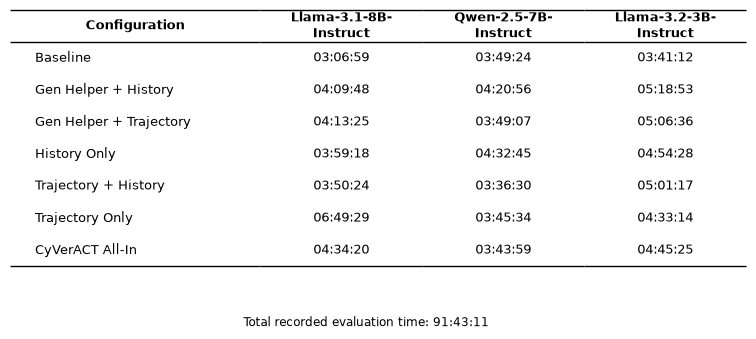

In [5]:
# ============================================================
# TOTAL EVALUATION TIME
# ============================================================

def fmt_time(s):
    h, r = divmod(int(s), 3600)
    m, s = divmod(r, 60)
    return f'{h:02d}:{m:02d}:{s:02d}'

data = []

for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        t = pd.to_numeric(dfs[model][config]['eval_time_s'], errors='coerce')
        row.append(fmt_time(t.sum()))
    data.append(row)

total_time = sum(
    pd.to_numeric(dfs[m][c]['eval_time_s'], errors='coerce').sum()
    for m in model_order for c in config_order
)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.7))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.10, 1, 0.90],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

fig.text(
    0.5, 0.025,
    f'Total recorded evaluation time: {fmt_time(total_time)}',
    ha='center', fontsize=8.5
)

os.makedirs('Figures/MultiDB_Dataset/Metric_Tables', exist_ok=True)

plt.savefig(
    'Figures/MultiDB_Dataset/Metric_Tables/total_evaluation_time.png',
    dpi=300, bbox_inches='tight', pad_inches=0.05
)

plt.show()

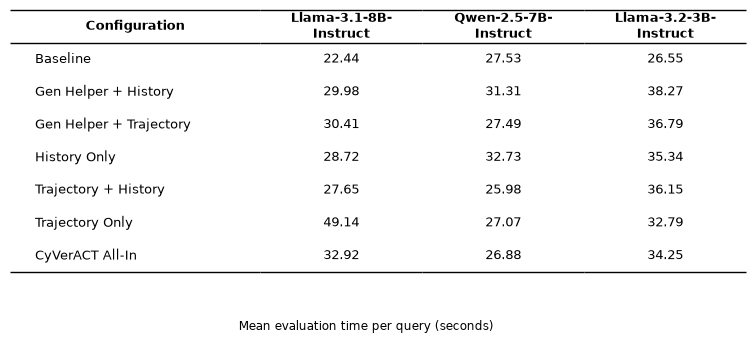

In [6]:
# ============================================================
# MEAN EVALUATION TIME PER QUERY
# ============================================================

data = []

for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        t = pd.to_numeric(dfs[model][config]['eval_time_s'], errors='coerce')
        row.append(f'{t.mean():.2f}')
    data.append(row)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.7))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.08, 1, 0.92],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

fig.text(
    0.5, 0.015,
    'Mean evaluation time per query (seconds)',
    ha='center', fontsize=8.5
)

plt.savefig(
    'Figures/MultiDB_Dataset/Metric_Tables/mean_eval_time_per_query.png',
    dpi=300, bbox_inches='tight', pad_inches=0.05
)

plt.show()

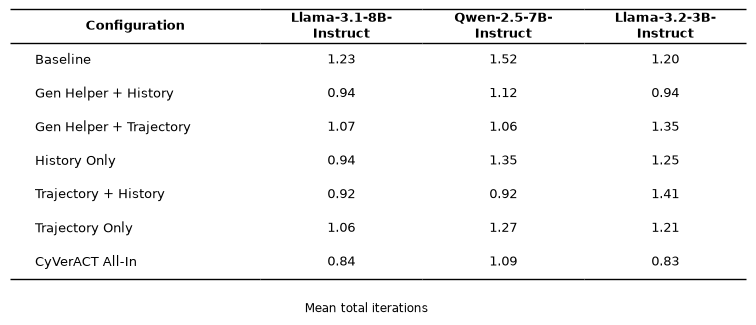

In [7]:
# ============================================================
# MEAN CORRECTOR ITERATIONS - KG VALID ONLY
# ============================================================

def count_corrector(path):
    return path_to_string(path).count('cypher_corrector')

data = []
for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        df = dfs[model][config]
        valid = df[df['final_kg_valid']]
        row.append(f"{valid['path'].apply(count_corrector).mean():.2f}")
    data.append(row)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.5))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0, 1, 1],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

fig.text(
    0.5, 0.015,
    'Mean total iterations',
    ha='center', fontsize=8.5
)

plt.savefig('Figures/MultiDB_Dataset/Metric_Tables/mean_corrector_iterations.png', dpi=300, bbox_inches='tight', pad_inches=0.05)

# plt.savefig('Figures/MultiDB_Dataset/Metric_Tables/mean_corrector_iterations.pdf', bbox_inches='tight', pad_inches=0.05)

plt.show()

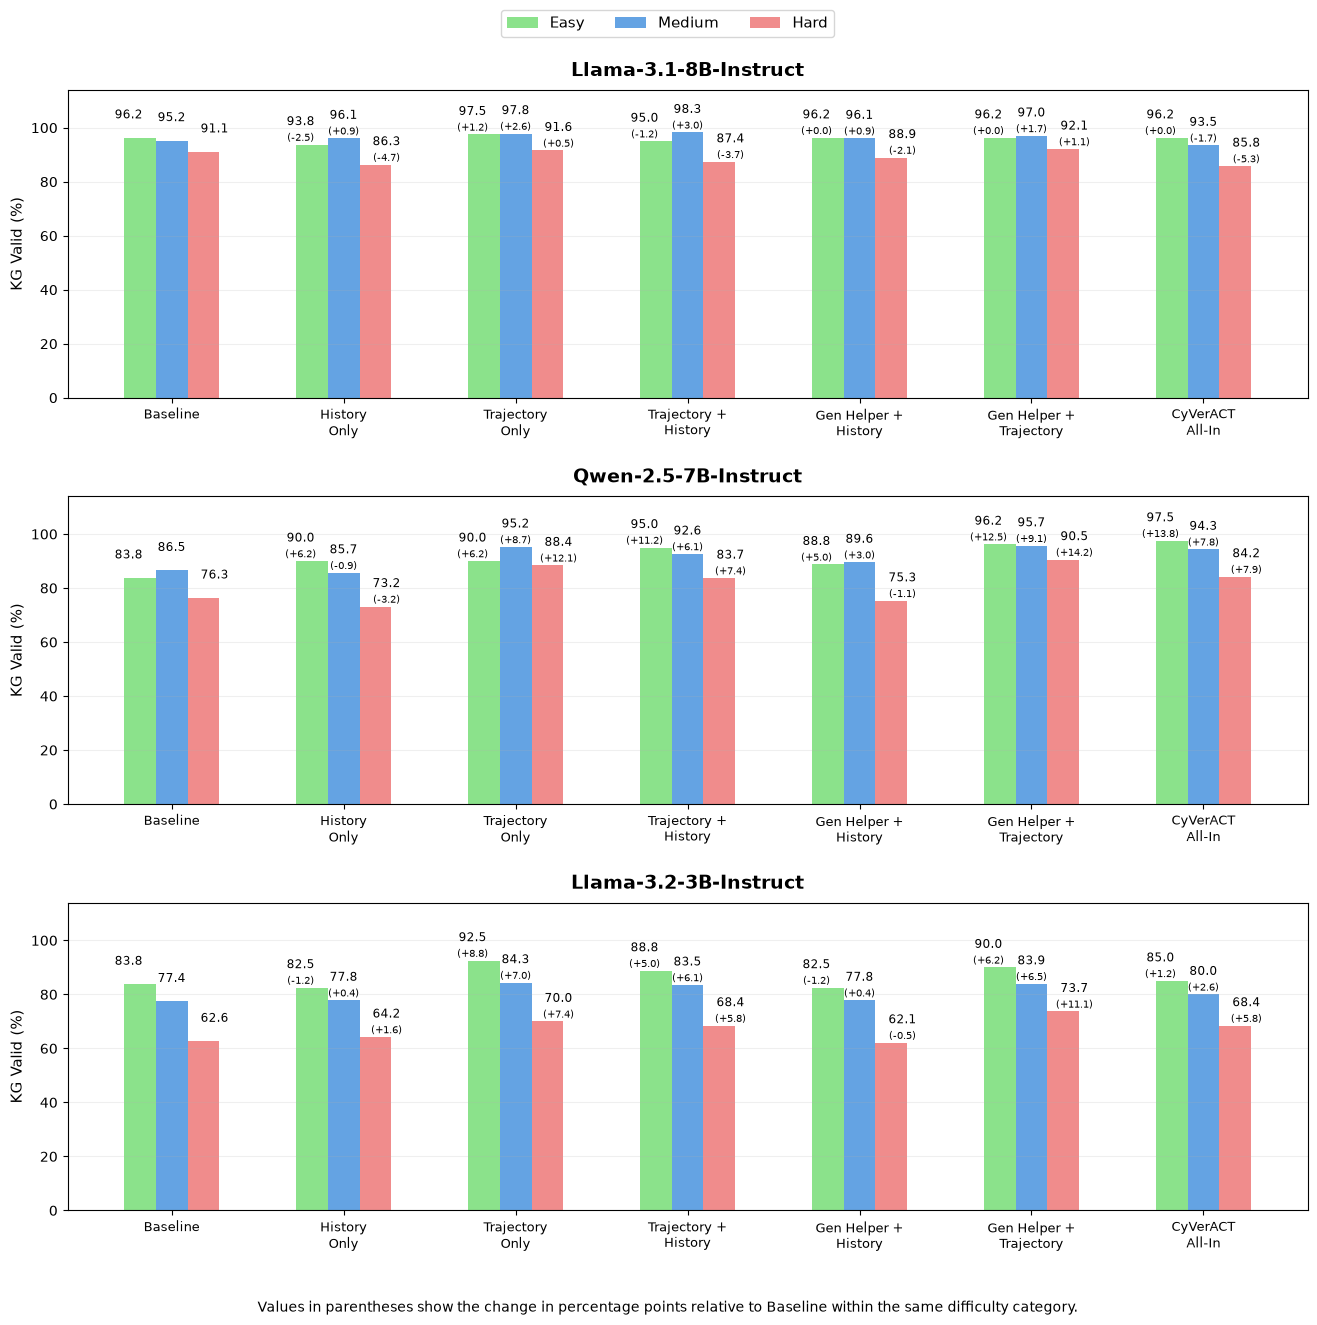

In [8]:
# ---------- KG VALID BY DIFFICULTY ----------

def categorize_complexity(query):
    q=str(query).upper()
    hard=r'\b(COLLECT|FILTER|UNWIND|WITH|FOREACH|REDUCE|CALL|YIELD|APOC)\b'
    medium=r'\b(ORDER BY|LIMIT|SKIP|COUNT|DISTINCT|EXISTS|IN|AND|OR|MIN|MAX|AVG|SUM)\b'
    if re.search(hard,q): return 'Hard'
    elif re.search(medium,q): return 'Medium'
    return 'Easy'

difficulty_order=['Easy','Medium','Hard']
difficulty_colors={'Easy':'#8BE28B','Medium':'#64A3E3','Hard':'#F08C8C'}

plot_config_order=['Baseline','History_Only','Trajectory_Only','Trajectory_History','Gen_Helper_History','Gen_Helper_Trajectory','All_In']
plot_config_labels={
    'Baseline':'Baseline','History_Only':'History\nOnly','Trajectory_Only':'Trajectory\nOnly',
    'Trajectory_History':'Trajectory +\nHistory','Gen_Helper_History':'Gen Helper +\nHistory',
    'Gen_Helper_Trajectory':'Gen Helper +\nTrajectory','All_In':'CyVerACT\nAll-In'
}

rows=[]
for model_key in model_order:
    for config_name in plot_config_order:
        df=pd.read_excel(metric_files[model_key][config_name])
        df['Difficulty']=df['cypher'].apply(categorize_complexity)
        df['final_kg_valid']=normalize_bool(df['is_KG_Valid_correct'])
        for difficulty in difficulty_order:
            subset=df[df['Difficulty']==difficulty]
            rows.append({'Model':model_key,'Configuration':config_name,'Difficulty':difficulty,'KG Valid (%)':subset['final_kg_valid'].mean()*100})

difficulty_results=pd.DataFrame(rows)

baseline_values={}
for model_key in model_order:
    baseline_values[model_key]={}
    for difficulty in difficulty_order:
        baseline_values[model_key][difficulty]=difficulty_results[
            (difficulty_results['Model']==model_key) &
            (difficulty_results['Configuration']=='Baseline') &
            (difficulty_results['Difficulty']==difficulty)
        ]['KG Valid (%)'].iloc[0]

difficulty_results['Delta']=difficulty_results.apply(lambda r:r['KG Valid (%)']-baseline_values[r['Model']][r['Difficulty']],axis=1)

fig,axes=plt.subplots(3,1,figsize=(16,13.5),sharey=True)

bar_width=0.20
x=np.arange(len(plot_config_order))*1.08
offsets={'Easy':-bar_width,'Medium':0,'Hard':bar_width}

value_offsets={'Easy':(-8,12),'Medium':(0,12),'Hard':(8,12)}
delta_offsets={'Easy':(-8,1),'Medium':(0,1),'Hard':(8,1)}

for ax,model_key in zip(axes,model_order):
    model_df=difficulty_results[difficulty_results['Model']==model_key]

    for difficulty in difficulty_order:
        values=[]; deltas=[]
        for config_name in plot_config_order:
            result=model_df[(model_df['Configuration']==config_name) & (model_df['Difficulty']==difficulty)]
            values.append(result['KG Valid (%)'].iloc[0])
            deltas.append(result['Delta'].iloc[0])

        bars=ax.bar(x+offsets[difficulty],values,width=bar_width,label=difficulty,color=difficulty_colors[difficulty])

        for i,(bar,value,delta) in enumerate(zip(bars,values,deltas)):
            xpos=bar.get_x()+bar.get_width()/2
            vx,vy=value_offsets[difficulty]

            ax.annotate(
                f'{value:.1f}',
                xy=(xpos,value),xytext=(vx,vy),textcoords='offset points',
                ha='center',va='bottom',fontsize=8.3,clip_on=False,zorder=6
            )

            if plot_config_order[i]!='Baseline':
                dx,dy=delta_offsets[difficulty]
                ax.annotate(
                    f'({delta:+.1f})',
                    xy=(xpos,value),xytext=(dx,dy),textcoords='offset points',
                    ha='center',va='bottom',fontsize=7.2,
                    bbox=dict(facecolor='white',edgecolor='none',alpha=0.80,pad=0.10),
                    clip_on=False,zorder=5
                )

    ax.set_title(model_names[model_key],fontsize=14,fontweight='bold',pad=10)
    ax.set_ylabel('KG Valid (%)',fontsize=11)
    ax.set_ylim(0,114)
    ax.set_xticks(x)
    ax.set_xticklabels([plot_config_labels[c] for c in plot_config_order],fontsize=9)
    ax.tick_params(axis='y',labelsize=10)
    ax.grid(axis='y',alpha=0.20)

handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=3,bbox_to_anchor=(0.5,0.985),fontsize=11,frameon=True)

fig.text(
    0.5,0.015,
    'Values in parentheses show the change in percentage points relative to Baseline within the same difficulty category.',
    ha='center',fontsize=10
)

plt.subplots_adjust(top=0.92,bottom=0.09,hspace=0.32)
plt.savefig('Figures/MultiDB_Dataset/Diagrams/kg_valid_by_difficulty.png', dpi=300,bbox_inches='tight')
plt.savefig('Figures/MultiDB_Dataset/Diagrams/kg_valid_by_difficulty.pdf', bbox_inches='tight')
plt.show()

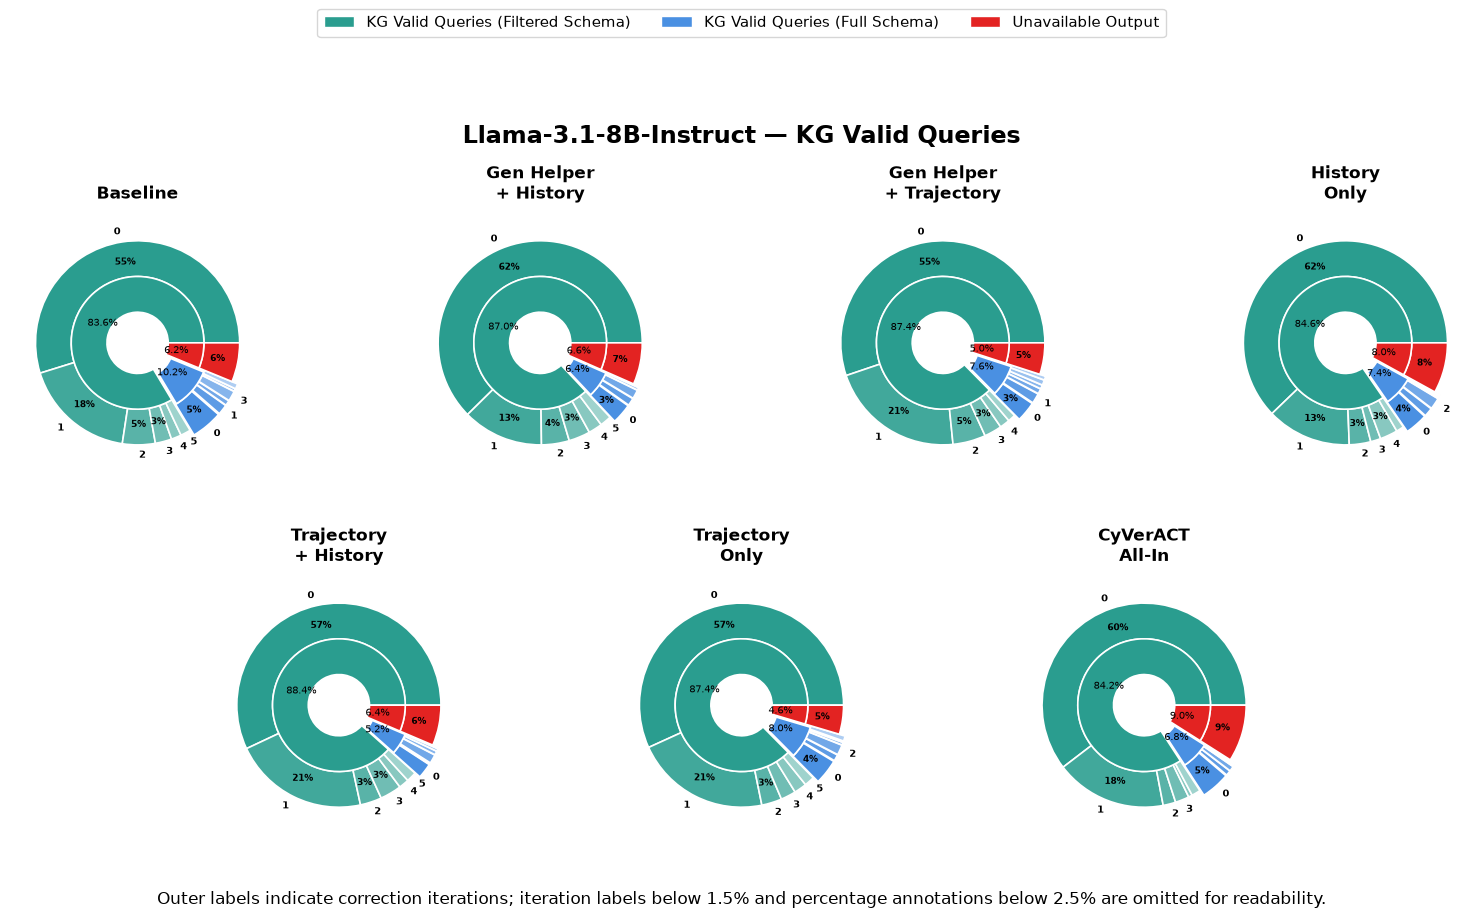

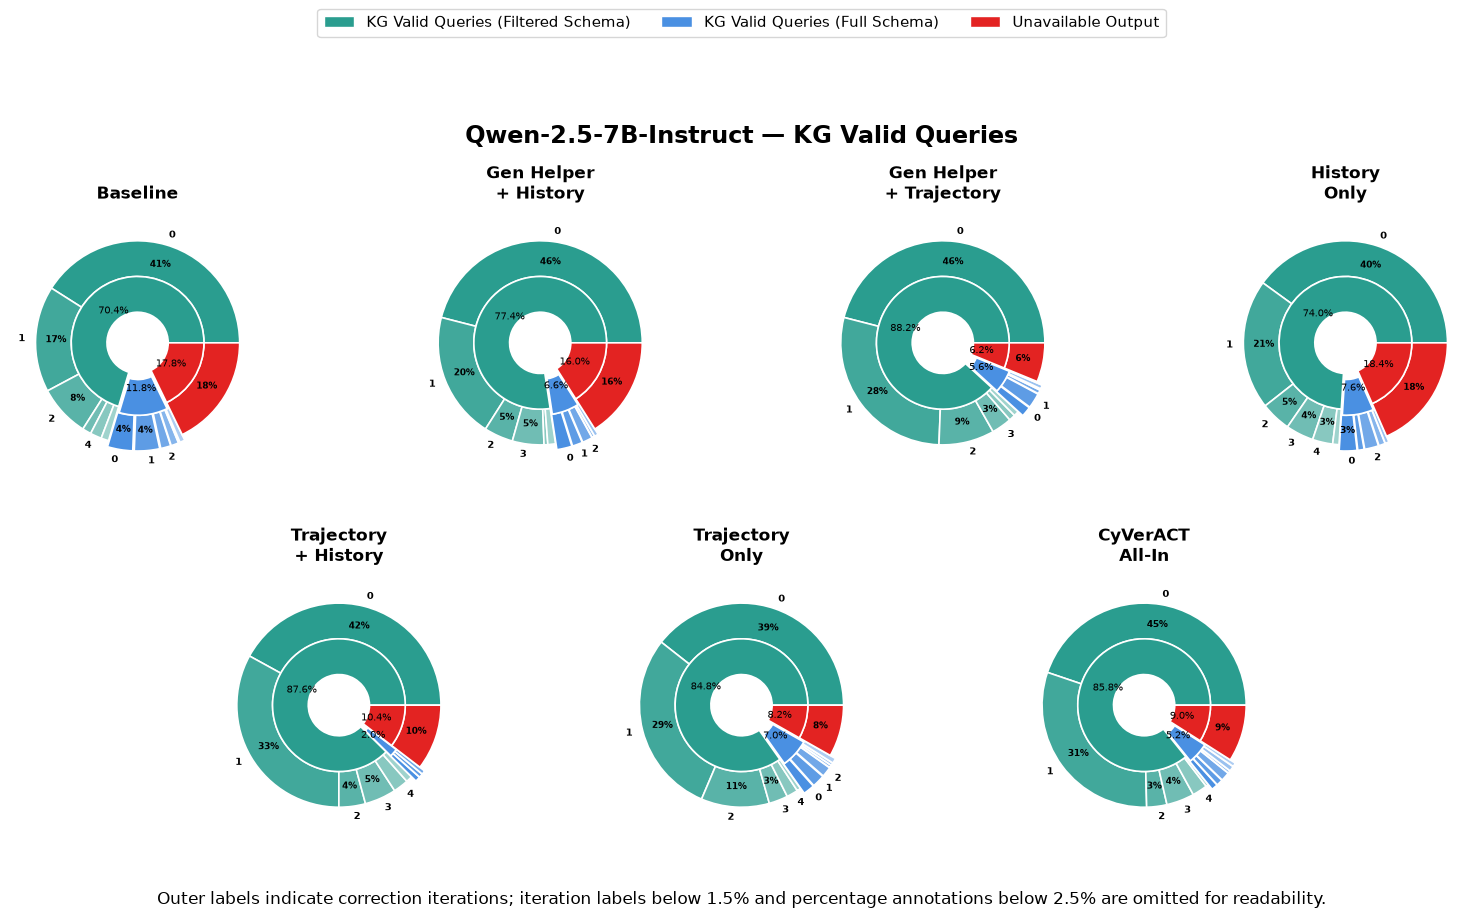

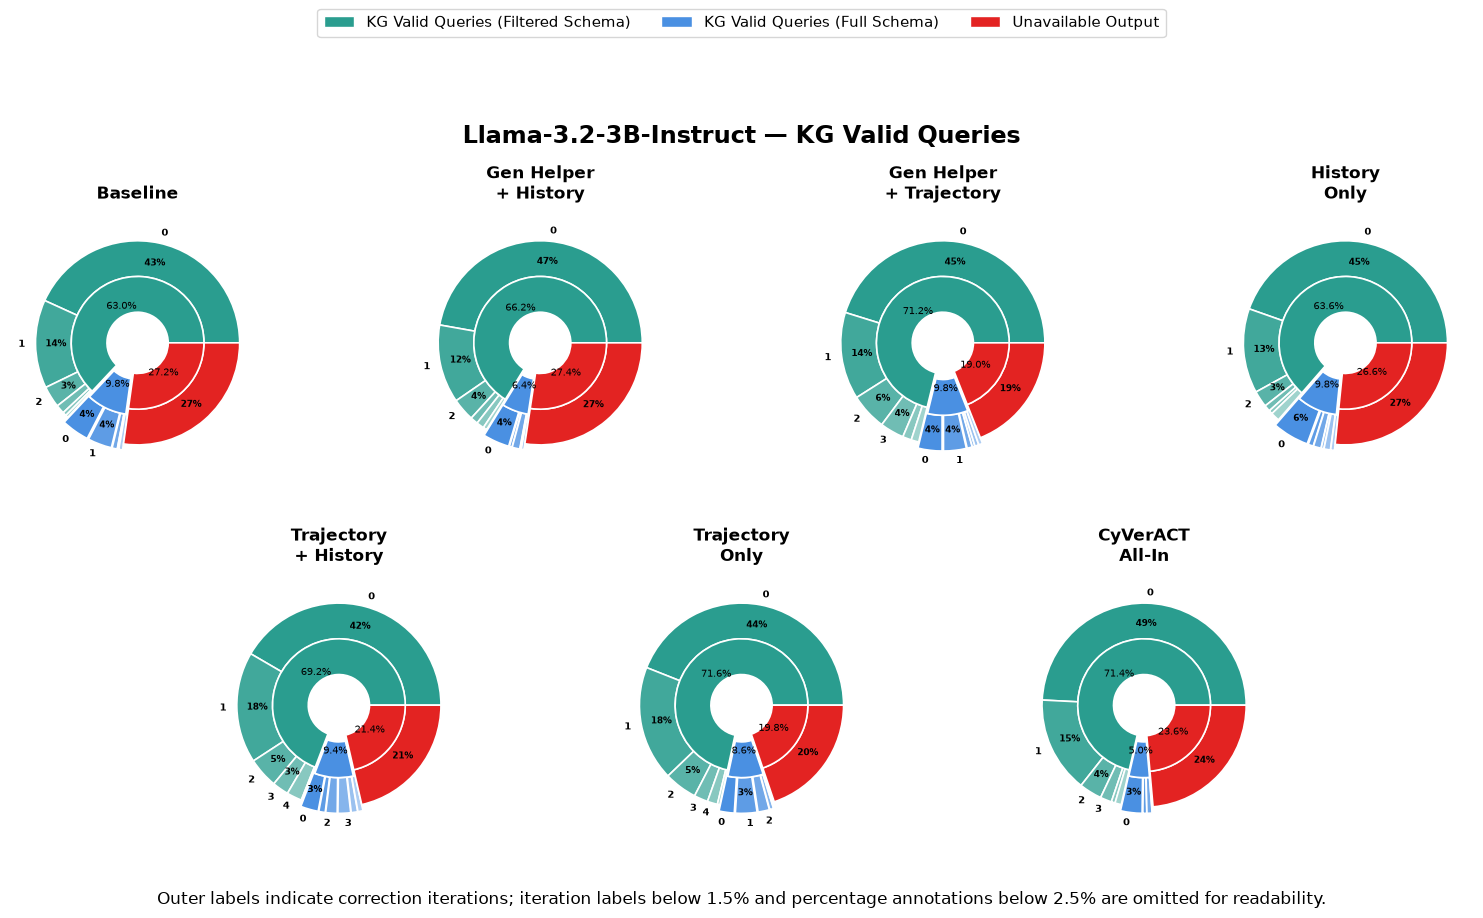

In [9]:
KG_FILTERED = 'KG Valid Queries (Filtered Schema)'
KG_FULL = 'KG Valid Queries (Full Schema)'
KG_UNAVAILABLE = 'Unavailable Output'

kg_categories = [KG_FILTERED, KG_FULL, KG_UNAVAILABLE]

kg_colors = {
    KG_FILTERED: COLOR_FILTERED,
    KG_FULL: COLOR_FULL,
    KG_UNAVAILABLE: COLOR_UNAVAILABLE
}

kg_legend = [
    Patch(facecolor=kg_colors[KG_FILTERED], edgecolor='white', label=KG_FILTERED),
    Patch(facecolor=kg_colors[KG_FULL], edgecolor='white', label=KG_FULL),
    Patch(facecolor=kg_colors[KG_UNAVAILABLE], edgecolor='white', label=KG_UNAVAILABLE)
]

MIN_ITER_LABEL_PCT = 1.5
MIN_OUTER_PCT = 2.5

def clean_outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= MIN_OUTER_PCT else ''

for model_key in model_order:
    fig = plt.figure(figsize=(17, 9.5))

    gs = fig.add_gridspec(
        2, 8,
        left=0.04, right=0.96,
        bottom=0.11, top=0.76,
        wspace=0.30, hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=kg_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=3,
        fontsize=11,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — KG Valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.855
    )

    ring_width = 0.35
    KG_GROUP_GAP = 0.06

    kg_explode_map = {
        KG_FILTERED: 0.00,
        KG_FULL: KG_GROUP_GAP,
        KG_UNAVAILABLE: 0.00
    }

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()

        df['PlotCategory'] = KG_UNAVAILABLE
        df.loc[df['SchemaPhase'] == 'Filtered', 'PlotCategory'] = KG_FILTERED
        df.loc[df['SchemaPhase'] == 'Full', 'PlotCategory'] = KG_FULL

        inner_sizes = []
        inner_colors = []
        inner_explode = []

        for category in kg_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(kg_colors[category])
                inner_explode.append(kg_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in kg_categories:
            sub_df = df[df['PlotCategory'] == category]

            if sub_df.empty:
                continue

            if category == KG_UNAVAILABLE:
                outer_sizes.append(len(sub_df))
                outer_colors.append(kg_colors[category])
                outer_labels.append('')
                outer_explode.append(kg_explode_map[category])
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .sort_index()
            )

            for iteration, count in iteration_counts.items():
                outer_sizes.append(count)
                outer_colors.append(
                    get_iteration_color(
                        kg_colors[category],
                        iteration
                    )
                )

                pct = (count / len(df)) * 100
                outer_labels.append(
                    str(iteration) if pct >= MIN_ITER_LABEL_PCT else ''
                )

                outer_explode.append(
                    kg_explode_map[category]
                )

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.10,
            autopct=clean_outer_autopct,
            pctdistance=0.80,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        _, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in inner_autotexts:
            text.set_fontsize(7)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels indicate correction iterations; iteration labels below 1.5% and percentage annotations below 2.5% are omitted for readability.',
        ha='center',
        fontsize=12
    )

    os.makedirs('Figures/MultiDB_Dataset/Diagrams', exist_ok=True)

    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/kg_valid_{model_key}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/kg_valid_{model_key}.pdf',
        bbox_inches='tight'
    )

    plt.show()

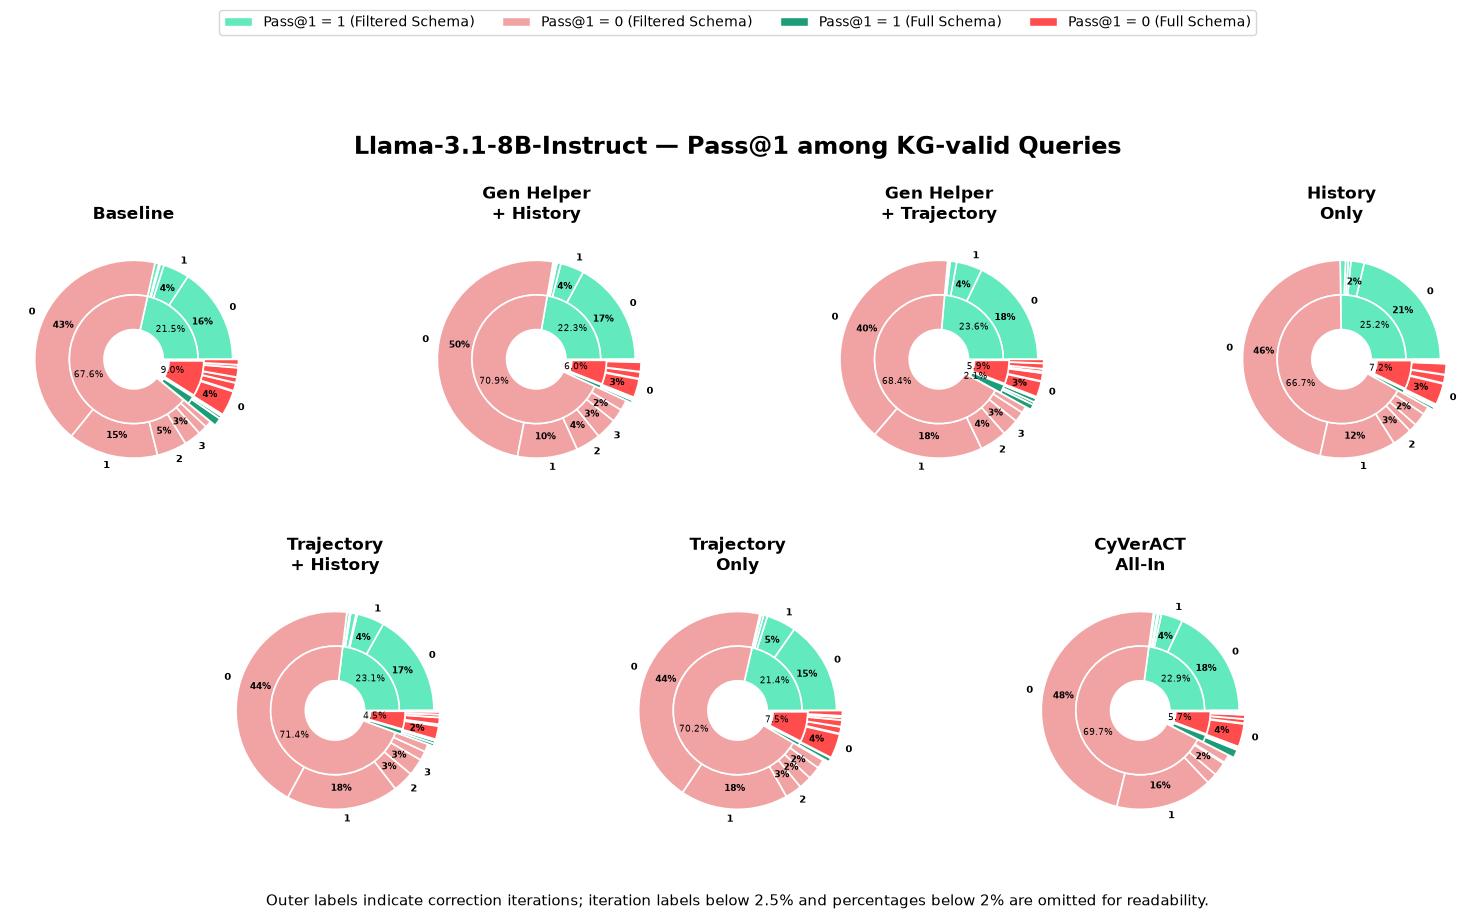

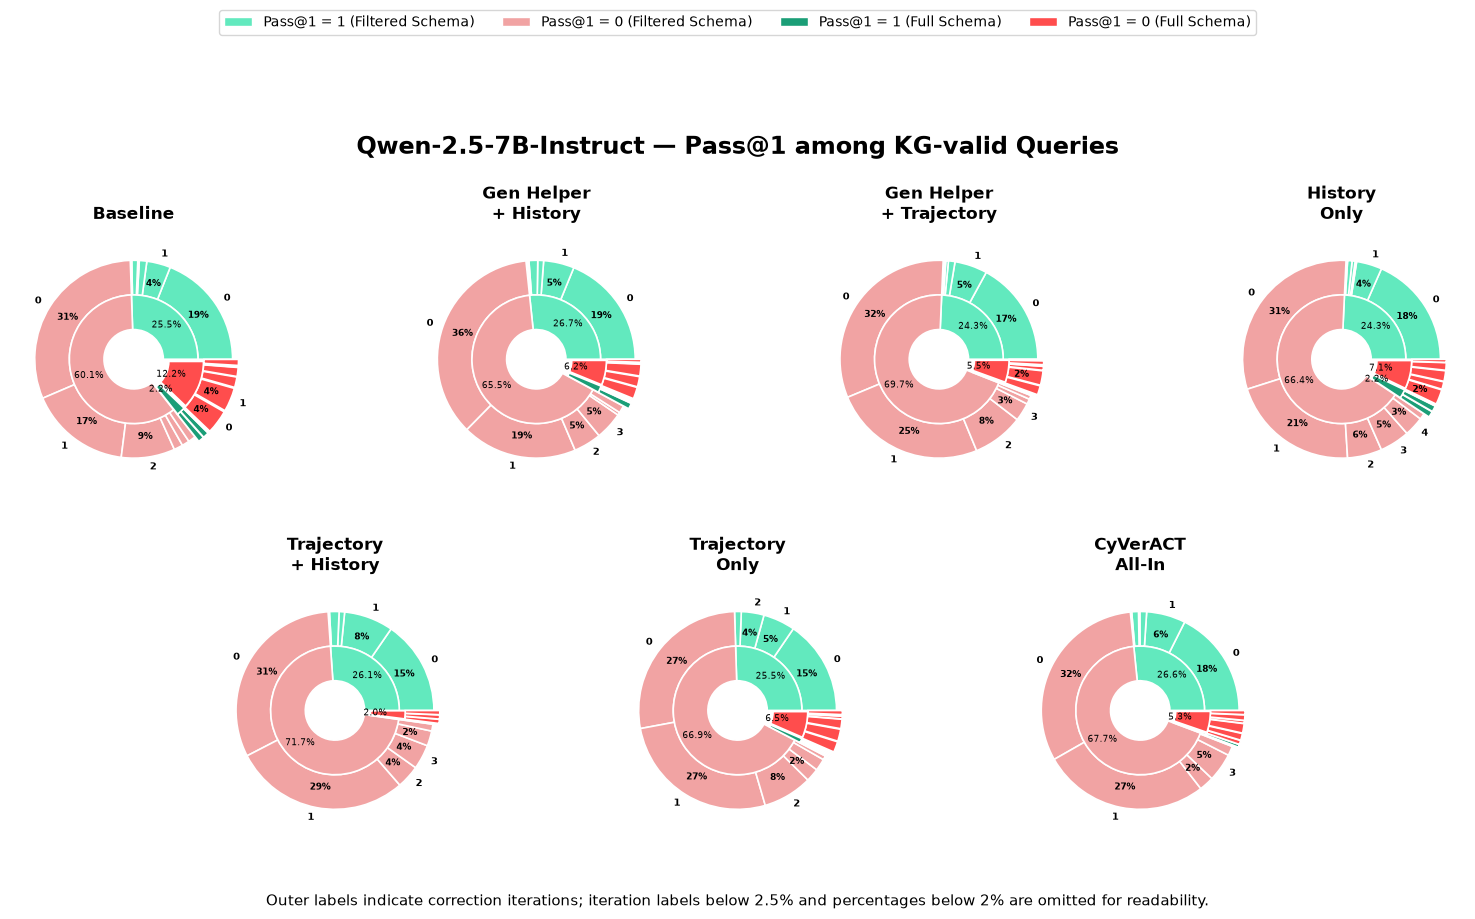

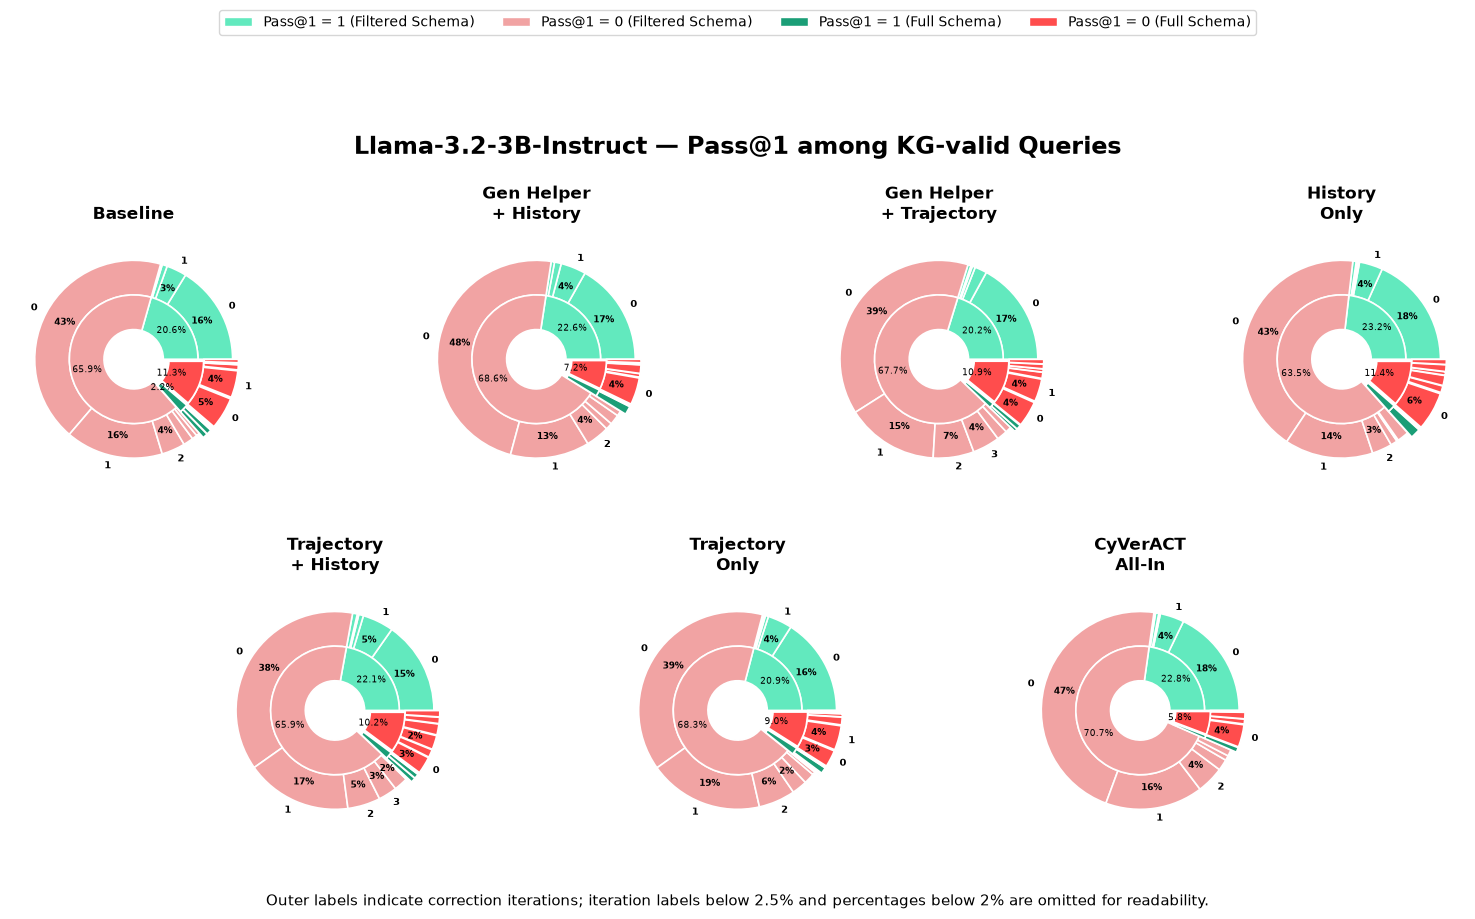

In [10]:
P1_FILTERED_SUCCESS = 'Pass@1 = 1 - Filtered'
P1_FILTERED_FAIL = 'Pass@1 = 0 - Filtered'
P1_FULL_SUCCESS = 'Pass@1 = 1 - Full'
P1_FULL_FAIL = 'Pass@1 = 0 - Full'

PASS1_FILTERED_SUCCESS_COLOR = "#62e9be"
PASS1_FULL_SUCCESS_COLOR = "#1b9e77"
PASS1_FILTERED_FAIL_COLOR = "#f1a3a3"
PASS1_FULL_FAIL_COLOR = "#ff4d4d"

pass_categories = [
    P1_FILTERED_SUCCESS,
    P1_FILTERED_FAIL,
    P1_FULL_SUCCESS,
    P1_FULL_FAIL
]

pass_colors = {
    P1_FILTERED_SUCCESS: PASS1_FILTERED_SUCCESS_COLOR,
    P1_FILTERED_FAIL: PASS1_FILTERED_FAIL_COLOR,
    P1_FULL_SUCCESS: PASS1_FULL_SUCCESS_COLOR,
    P1_FULL_FAIL: PASS1_FULL_FAIL_COLOR
}

pass_legend = [
    Patch(facecolor=PASS1_FILTERED_SUCCESS_COLOR, edgecolor='white',
          label='Pass@1 = 1 (Filtered Schema)'),
    Patch(facecolor=PASS1_FILTERED_FAIL_COLOR, edgecolor='white',
          label='Pass@1 = 0 (Filtered Schema)'),
    Patch(facecolor=PASS1_FULL_SUCCESS_COLOR, edgecolor='white',
          label='Pass@1 = 1 (Full Schema)'),
    Patch(facecolor=PASS1_FULL_FAIL_COLOR, edgecolor='white',
          label='Pass@1 = 0 (Full Schema)')
]

ITERATION_ORDER = [0, 1, 2, 3, 4, 5]
PIE_STARTANGLE = 0
PIE_COUNTERCLOCK = True
GROUP_GAP = 0.06

MIN_ITER_LABEL_PCT = 2.5
MIN_PERCENTAGE_PCT = 2.0

pass_explode_map = {
    P1_FILTERED_SUCCESS: 0.00,
    P1_FILTERED_FAIL: 0.00,
    P1_FULL_SUCCESS: GROUP_GAP,
    P1_FULL_FAIL: GROUP_GAP
}

def pass1_outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= MIN_PERCENTAGE_PCT else ''

def pass1_inner_autopct(pct):
    return f'{pct:.1f}%' if pct >= MIN_PERCENTAGE_PCT else ''

for model_key in model_order:
    fig = plt.figure(figsize=(17, 9.5))
    gs = fig.add_gridspec(
        2, 8,
        left=0.04, right=0.96,
        bottom=0.11, top=0.74,
        wspace=0.30, hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=pass_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Pass@1 among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()
        df = df[df['SchemaPhase'].isin(['Filtered', 'Full'])].copy()

        metric = pd.to_numeric(df['Pass@1 Output'], errors='coerce').fillna(0)

        df['PlotCategory'] = None
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(1), 'PlotCategory'] = P1_FILTERED_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(0), 'PlotCategory'] = P1_FILTERED_FAIL
        df.loc[(df['SchemaPhase'] == 'Full') & metric.eq(1), 'PlotCategory'] = P1_FULL_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Full') & metric.eq(0), 'PlotCategory'] = P1_FULL_FAIL

        inner_sizes = []
        inner_colors = []
        inner_categories = []
        inner_explode = []

        for category in pass_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(pass_colors[category])
                inner_categories.append(category)
                inner_explode.append(pass_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in pass_categories:
            sub_df = df[df['PlotCategory'] == category]

            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .to_dict()
            )

            for iteration in ITERATION_ORDER:
                count = iteration_counts.get(iteration, 0)

                if count > 0:
                    outer_sizes.append(count)
                    outer_colors.append(pass_colors[category])

                    pct = (count / len(df)) * 100
                    outer_labels.append(
                        str(iteration) if pct >= MIN_ITER_LABEL_PCT else ''
                    )

                    outer_explode.append(pass_explode_map[category])

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.10,
            autopct=pass1_outer_autopct,
            pctdistance=0.79,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        inner_wedges, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct=pass1_inner_autopct,
            pctdistance=0.60,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        inner_radii = {
            P1_FILTERED_SUCCESS: 0.48,
            P1_FILTERED_FAIL: 0.48,
            P1_FULL_SUCCESS: 0.35,
            P1_FULL_FAIL: 0.35
        }

        for wedge, text, category in zip(inner_wedges, inner_autotexts, inner_categories):
            angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
            radius = inner_radii[category]
            cx, cy = wedge.center
            text.set_position((cx + radius * np.cos(angle), cy + radius * np.sin(angle)))
            text.set_fontsize(6.5)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels indicate correction iterations; iteration labels below 2.5% and percentages below 2% are omitted for readability.',
        ha='center',
        fontsize=11
    )

    os.makedirs('Figures/MultiDB_Dataset/Diagrams', exist_ok=True)

    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/pass1_kg_valid_{model_key}.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/pass1_kg_valid_{model_key}.pdf',
        bbox_inches='tight'
    )

    plt.show()

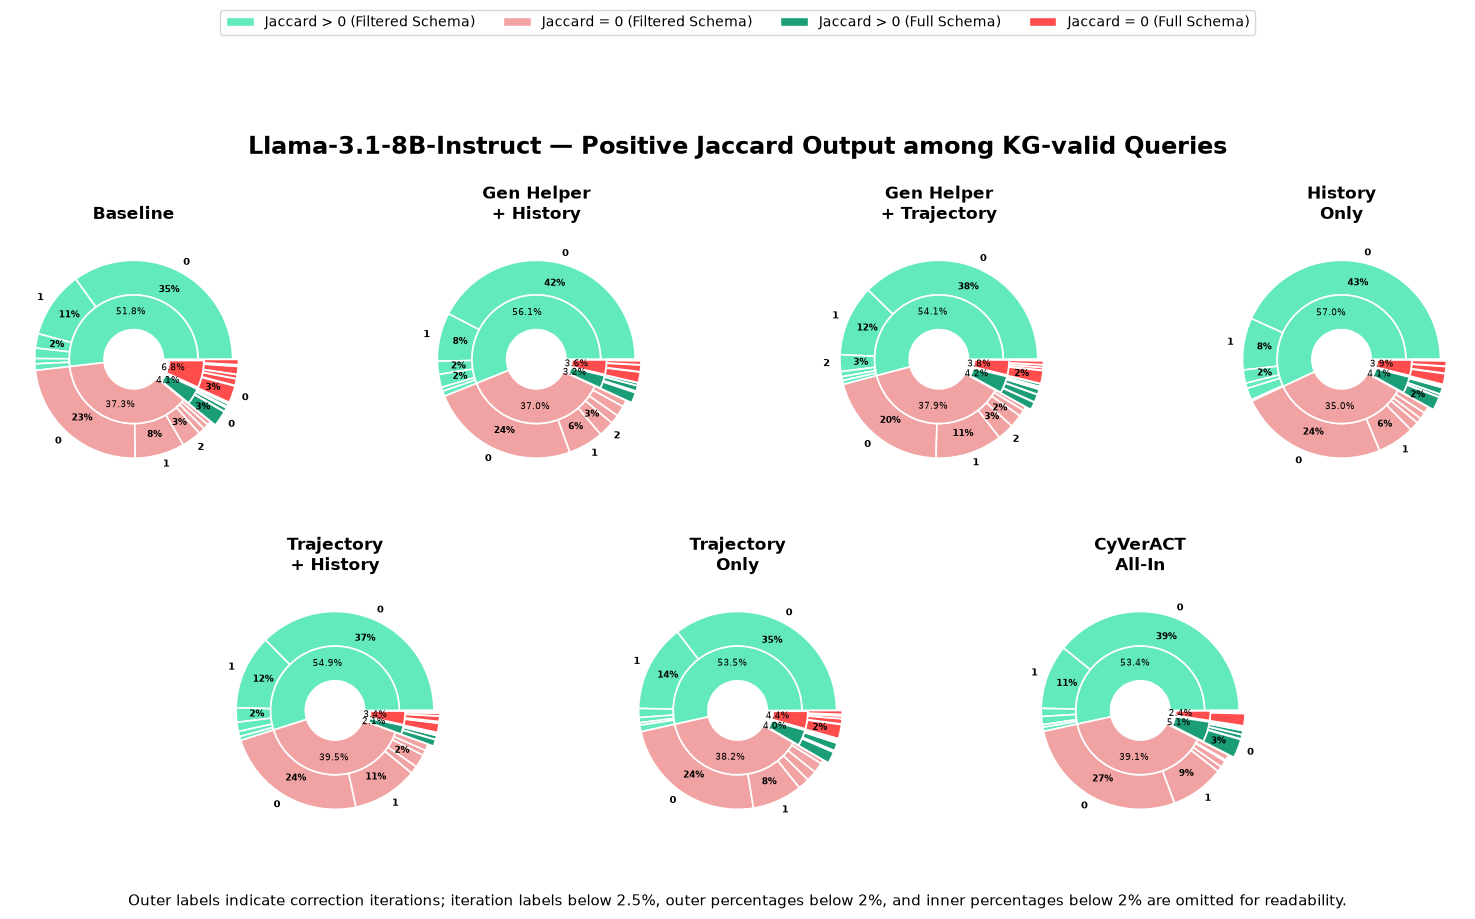

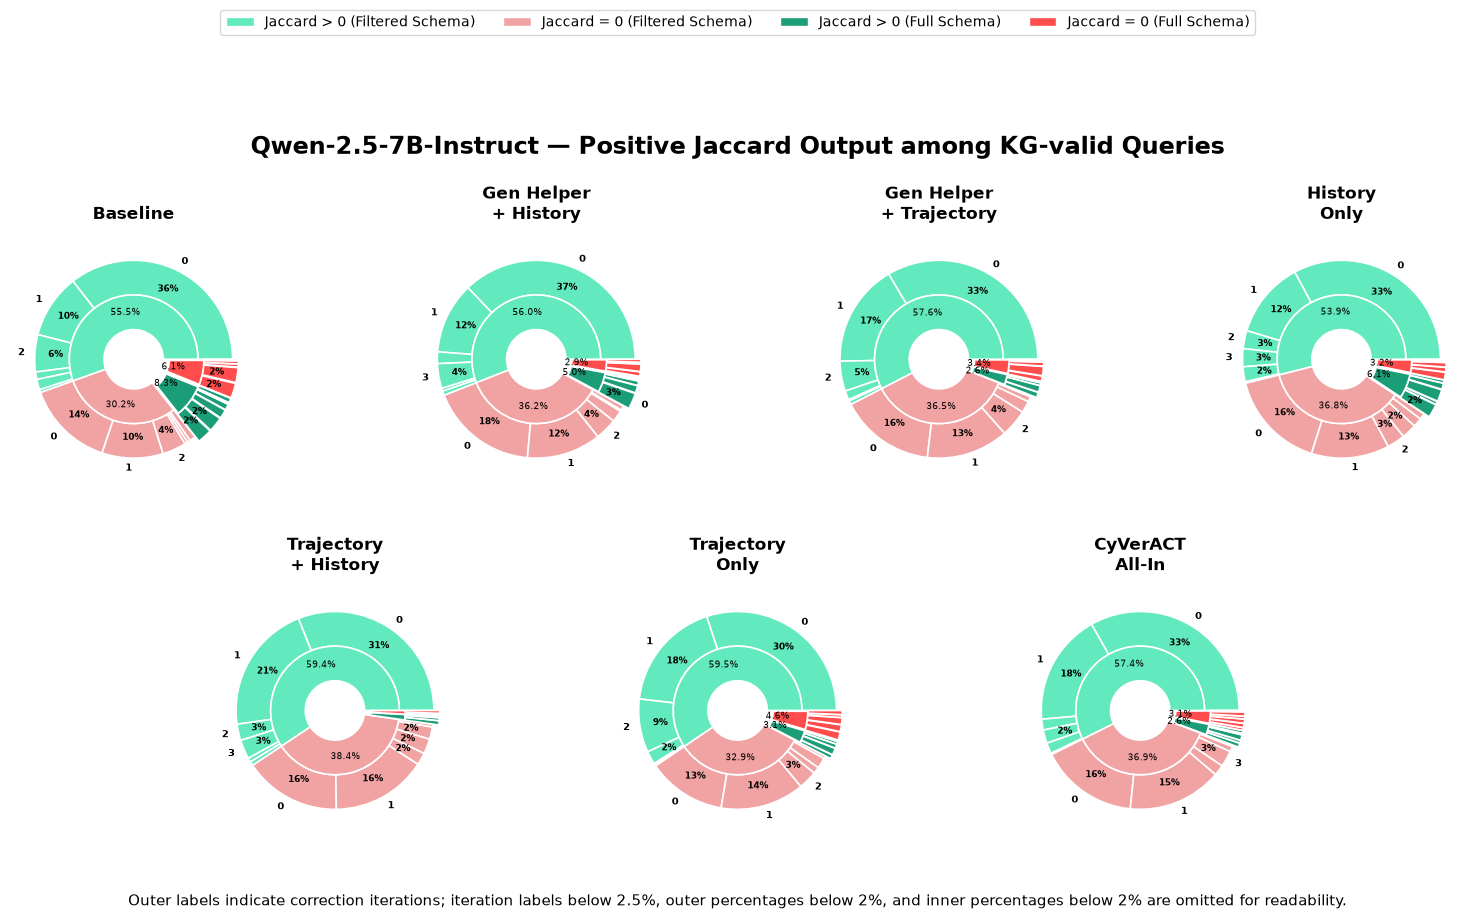

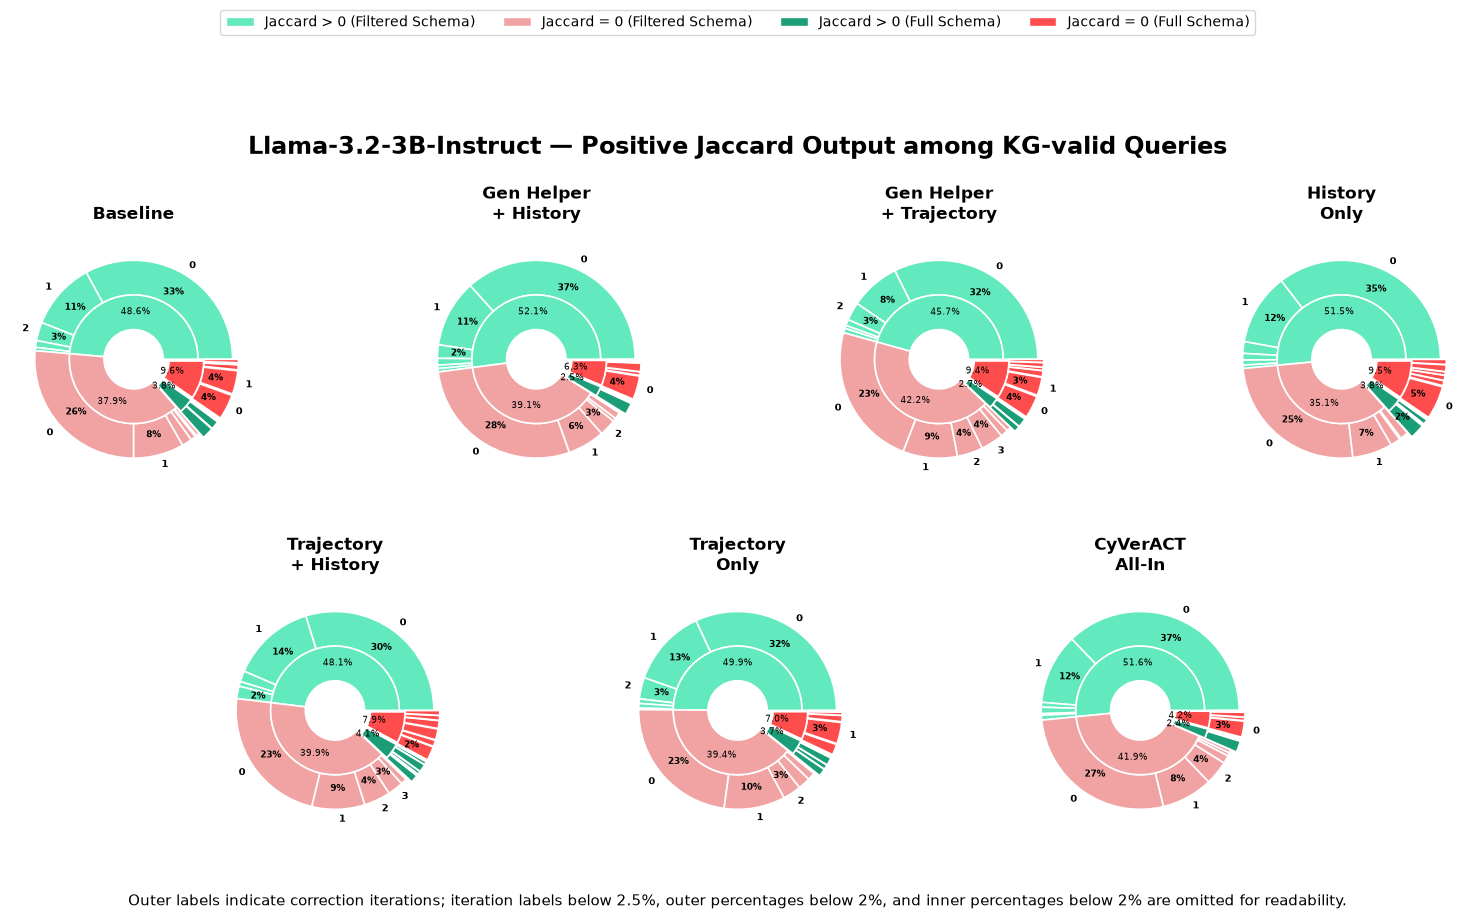

In [11]:
J_FILTERED_SUCCESS = 'Jaccard > 0 - Filtered'
J_FILTERED_FAIL = 'Jaccard = 0 - Filtered'
J_FULL_SUCCESS = 'Jaccard > 0 - Full'
J_FULL_FAIL = 'Jaccard = 0 - Full'

JACCARD_FILTERED_SUCCESS_COLOR = "#62e9be"
JACCARD_FULL_SUCCESS_COLOR = "#1b9e77"
JACCARD_FILTERED_FAIL_COLOR = "#f1a3a3"
JACCARD_FULL_FAIL_COLOR = "#ff4d4d"

jaccard_categories = [
    J_FILTERED_SUCCESS,
    J_FILTERED_FAIL,
    J_FULL_SUCCESS,
    J_FULL_FAIL
]

jaccard_colors = {
    J_FILTERED_SUCCESS: JACCARD_FILTERED_SUCCESS_COLOR,
    J_FILTERED_FAIL: JACCARD_FILTERED_FAIL_COLOR,
    J_FULL_SUCCESS: JACCARD_FULL_SUCCESS_COLOR,
    J_FULL_FAIL: JACCARD_FULL_FAIL_COLOR
}

jaccard_legend = [
    Patch(facecolor=JACCARD_FILTERED_SUCCESS_COLOR, edgecolor='white', label='Jaccard > 0 (Filtered Schema)'),
    Patch(facecolor=JACCARD_FILTERED_FAIL_COLOR, edgecolor='white', label='Jaccard = 0 (Filtered Schema)'),
    Patch(facecolor=JACCARD_FULL_SUCCESS_COLOR, edgecolor='white', label='Jaccard > 0 (Full Schema)'),
    Patch(facecolor=JACCARD_FULL_FAIL_COLOR, edgecolor='white', label='Jaccard = 0 (Full Schema)')
]

ITERATION_ORDER = [0, 1, 2, 3, 4, 5]
PIE_STARTANGLE = 0
PIE_COUNTERCLOCK = True
GROUP_GAP = 0.06

MIN_ITER_LABEL_PCT = 2.5
MIN_OUTER_PCT = 2.0
MIN_INNER_PCT = 2.0

jaccard_explode_map = {
    J_FILTERED_SUCCESS: 0.00,
    J_FILTERED_FAIL: 0.00,
    J_FULL_SUCCESS: GROUP_GAP,
    J_FULL_FAIL: GROUP_GAP
}

def jaccard_outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= MIN_OUTER_PCT else ''

def jaccard_inner_autopct(pct):
    return f'{pct:.1f}%' if pct >= MIN_INNER_PCT else ''

for model_key in model_order:
    fig = plt.figure(figsize=(17, 9.5))
    gs = fig.add_gridspec(
        2, 8,
        left=0.04, right=0.96,
        bottom=0.11, top=0.74,
        wspace=0.30, hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=jaccard_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Positive Jaccard Output among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()
        df = df[df['SchemaPhase'].isin(['Filtered', 'Full'])].copy()

        metric = pd.to_numeric(df['Jaccard Output'], errors='coerce').fillna(0)

        df['PlotCategory'] = None
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.gt(0), 'PlotCategory'] = J_FILTERED_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(0), 'PlotCategory'] = J_FILTERED_FAIL
        df.loc[(df['SchemaPhase'] == 'Full') & metric.gt(0), 'PlotCategory'] = J_FULL_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Full') & metric.eq(0), 'PlotCategory'] = J_FULL_FAIL

        inner_sizes = []
        inner_colors = []
        inner_categories = []
        inner_explode = []

        for category in jaccard_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(jaccard_colors[category])
                inner_categories.append(category)
                inner_explode.append(jaccard_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in jaccard_categories:
            sub_df = df[df['PlotCategory'] == category]

            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .to_dict()
            )

            for iteration in ITERATION_ORDER:
                count = iteration_counts.get(iteration, 0)

                if count > 0:
                    outer_sizes.append(count)
                    outer_colors.append(jaccard_colors[category])

                    pct = (count / len(df)) * 100
                    outer_labels.append(
                        str(iteration) if pct >= MIN_ITER_LABEL_PCT else ''
                    )

                    outer_explode.append(jaccard_explode_map[category])

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.10,
            autopct=jaccard_outer_autopct,
            pctdistance=0.79,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        inner_wedges, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct=jaccard_inner_autopct,
            pctdistance=0.60,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        inner_radii = {
            J_FILTERED_SUCCESS: 0.48,
            J_FILTERED_FAIL: 0.48,
            J_FULL_SUCCESS: 0.35,
            J_FULL_FAIL: 0.35
        }

        for wedge, text, category in zip(inner_wedges, inner_autotexts, inner_categories):
            angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
            radius = inner_radii[category]
            cx, cy = wedge.center
            text.set_position((cx + radius * np.cos(angle), cy + radius * np.sin(angle)))
            text.set_fontsize(6.5)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels indicate correction iterations; iteration labels below 2.5%, outer percentages below 2%, and inner percentages below 2% are omitted for readability.',
        ha='center',
        fontsize=11
    )

    os.makedirs('Figures/MultiDB_Dataset/Diagrams', exist_ok=True)

    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/jaccard_kg_valid_{model_key}.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.savefig(
        f'Figures/MultiDB_Dataset/Diagrams/jaccard_kg_valid_{model_key}.pdf',
        bbox_inches='tight'
    )

    plt.show()

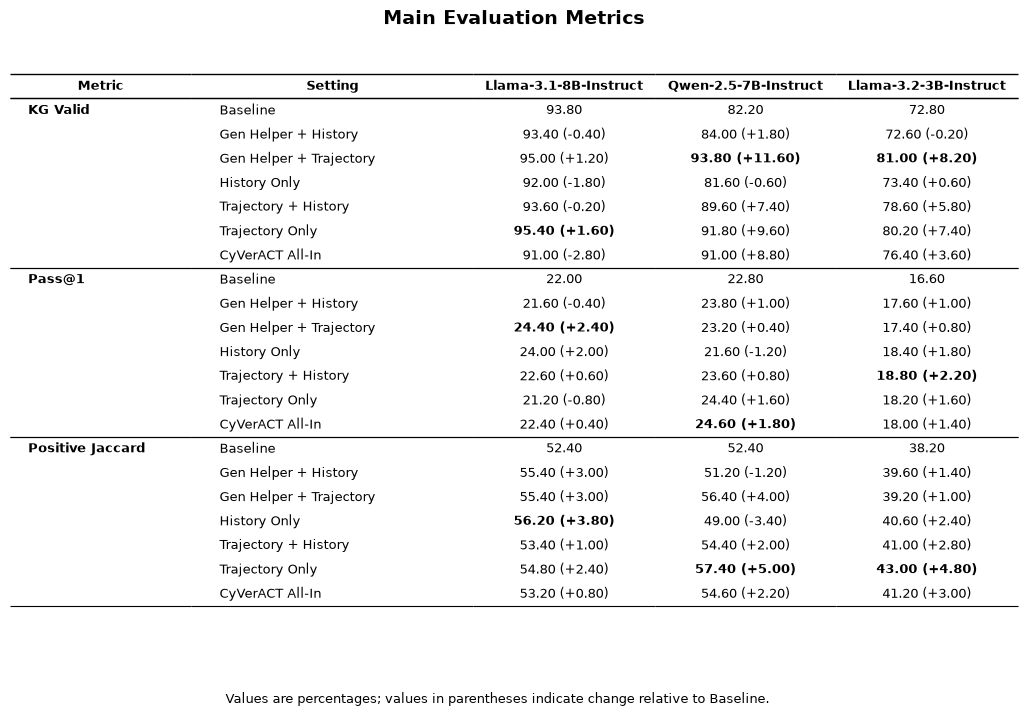

Saved: Figures/MultiDB_Dataset/Metric_Tables/main_metrics_table.png


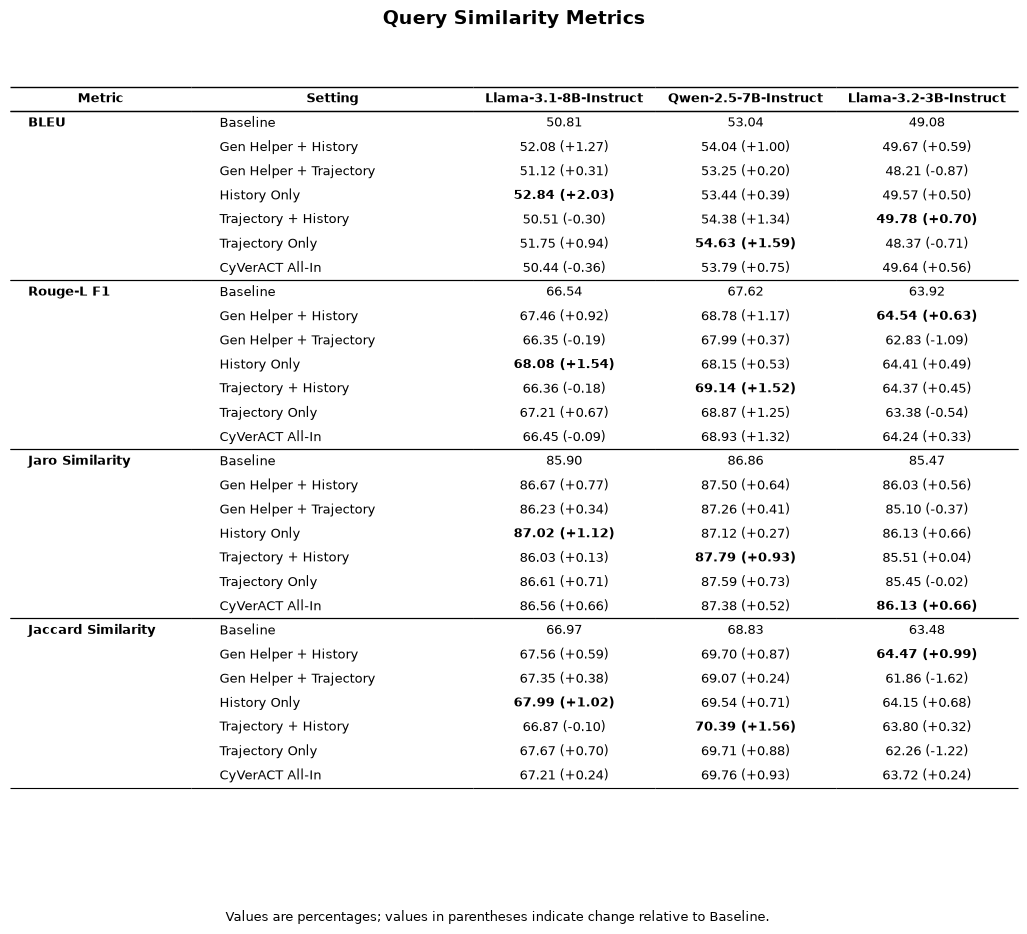

Saved: Figures/MultiDB_Dataset/Metric_Tables/similarity_metrics_table.png


In [12]:
os.makedirs('Figures//MultiDB_Dataset/Diagrams', exist_ok=True)
os.makedirs('Figures//MultiDB_Dataset/Metric_Tables', exist_ok=True)

table_config_names = {
    'Baseline': 'Baseline',
    'Gen_Helper_History': 'Gen Helper + History',
    'Gen_Helper_Trajectory': 'Gen Helper + Trajectory',
    'History_Only': 'History Only',
    'Trajectory_History': 'Trajectory + History',
    'Trajectory_Only': 'Trajectory Only',
    'All_In': 'CyVerACT All-In'
}

def create_metric_table(metrics, title, filename):
    rows = []
    numeric_rows = []

    for metric in metrics:
        for idx, config_name in enumerate(config_order):
            row = {
                'Metric': metric if idx == 0 else '',
                'Setting': table_config_names[config_name]
            }

            numeric_row = {
                'Metric': metric,
                'Setting': table_config_names[config_name]
            }

            for model_key in model_order:
                column = model_names[model_key]
                value = results[model_key][config_name][metric]
                numeric_row[column] = value

                if config_name == 'Baseline':
                    row[column] = f'{value:.2f}'
                else:
                    baseline = results[model_key]['Baseline'][metric]
                    row[column] = f'{value:.2f} ({value - baseline:+.2f})'

            rows.append(row)
            numeric_rows.append(numeric_row)

    display_df = pd.DataFrame(rows)
    numeric_df = pd.DataFrame(numeric_rows)

    fig_height = max(7, len(display_df) * 0.36)
    fig, ax = plt.subplots(figsize=(13, fig_height))
    ax.axis('off')

    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        cellLoc='center',
        colLoc='center',
        loc='center',
        colWidths=[0.18, 0.28, 0.18, 0.18, 0.18]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1, 1.45)

    n_cols = len(display_df.columns)

    for col in range(n_cols):
        cell = table[(0, col)]
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
        cell.set_linewidth(1.0)

    for row_idx in range(1, len(display_df) + 1):
        config_idx = (row_idx - 1) % len(config_order)

        for col in range(n_cols):
            cell = table[(row_idx, col)]
            cell.visible_edges = ''

            if config_idx == 0:
                cell.visible_edges = 'T'
                cell.set_linewidth(0.8)

            if config_idx == len(config_order) - 1:
                cell.visible_edges += 'B'
                cell.set_linewidth(0.8)

        table[(row_idx, 0)].get_text().set_ha('left')
        table[(row_idx, 1)].get_text().set_ha('left')

        if config_idx == 0:
            table[(row_idx, 0)].get_text().set_weight('bold')

    for metric_idx, metric in enumerate(metrics):
        metric_rows = numeric_df.index[numeric_df['Metric'] == metric]

        for model_idx, model_key in enumerate(model_order):
            column = model_names[model_key]
            values = numeric_df.loc[metric_rows, column]
            best = values.max()

            for dataframe_idx in values[np.isclose(values, best)].index:
                table[(dataframe_idx + 1, model_idx + 2)].get_text().set_weight('bold')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=18)

    fig.text(
        0.5,
        0.015,
        'Values are percentages; values in parentheses indicate change relative to Baseline.',
        ha='center',
        fontsize=9
    )

    plt.savefig(f'Figures/MultiDB_Dataset/Metric_Tables/{filename}.png', dpi=300, bbox_inches='tight')
    #plt.savefig(f'Figures/MultiDB_Dataset/Metric_Tables/{filename}.pdf', bbox_inches='tight')
    plt.show()

    print(f'Saved: Figures/MultiDB_Dataset/Metric_Tables/{filename}.png')

main_metrics = [
'KG Valid',
'Pass@1',
'Positive Jaccard',
]

similarity_metrics = [
    'BLEU',
    'Rouge-L F1',
    'Jaro Similarity',
    'Jaccard Similarity'
]

create_metric_table(
    main_metrics,
    'Main Evaluation Metrics',
    'main_metrics_table'
)

create_metric_table(
    similarity_metrics,
    'Query Similarity Metrics',
    'similarity_metrics_table'
)

# END OF DIAGRAMS